# Laboratório – EDA e Feature Engineering
## Dataset Titanic

**Disciplina:** Inteligência Artificial – CCI620

**Objetivo:** analisar quais fatores e perfis demográficos estiveram associados a uma maior probabilidade de sobrevivência no naufrágio do RMS Titanic, e preparar os dados para etapas futuras de modelagem preditiva.

**Estrutura do notebook**
1. Carga e visualização inicial
2. Análise Exploratória de Dados (EDA)
3. Tratamento e limpeza
4. Feature Engineering
5. Conclusões

## 1. Carga e visualização inicial

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

df = sns.load_dataset("titanic")

# visualização inicial
print(f"Dimensões do DataFrame: {df.shape}")
df.head()

Dimensões do DataFrame: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### Dicionário de dados

| Coluna | Descrição |
|---|---|
| `survived` | 0 = não sobreviveu, 1 = sobreviveu (**variável alvo**) |
| `pclass` / `class` | Classe do bilhete (1, 2, 3 / First, Second, Third) |
| `sex` | Sexo |
| `age` | Idade em anos |
| `sibsp` | Nº de irmãos/cônjuges a bordo |
| `parch` | Nº de pais/filhos a bordo |
| `fare` | Tarifa paga |
| `embarked` / `embark_town` | Porto de embarque (C, Q, S / Cherbourg, Queenstown, Southampton) |
| `who` | man, woman ou child |
| `adult_male` | Booleano: homem adulto |
| `deck` | Convés da cabine |
| `alive` | yes/no (equivalente a `survived`) |
| `alone` | Booleano: viajava sozinho |

## 2. Análise Exploratória de Dados (EDA)

### 2.1 Estrutura dos dados

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [3]:
# Tipos de dados e cardinalidade de cada coluna
pd.DataFrame({
    "dtype": df.dtypes,
    "valores_unicos": df.nunique(),
    "exemplo": df.iloc[0],
})

,dtype,valores_unicos,exemplo
survived,int64,2,0
pclass,int64,3,3
sex,str,2,male
age,float64,88,22.0
sibsp,int64,7,1
parch,int64,7,0
fare,float64,248,7.25
embarked,str,3,S
class,category,3,Third
who,str,3,man


### 2.2 Valores em falta (missing values)

,qtd,percentual (%)
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


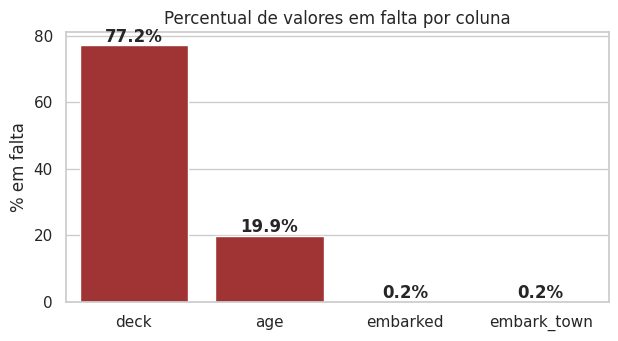

In [4]:
faltantes = pd.DataFrame({
    "qtd": df.isna().sum(),
    "percentual (%)": (df.isna().mean() * 100).round(2),
})
faltantes = faltantes[faltantes["qtd"] > 0].sort_values("qtd", ascending=False)
display(faltantes)

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=faltantes.index, y=faltantes["percentual (%)"], color="firebrick", ax=ax)
for i, v in enumerate(faltantes["percentual (%)"]):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")
ax.set_title("Percentual de valores em falta por coluna")
ax.set_ylabel("% em falta")
ax.set_xlabel("")
plt.show()

### 2.3 Medidas descritivas

In [5]:
# Variáveis numéricas: média, mediana, desvio padrão, quartis
desc = df.describe().T
desc["mediana"] = df.select_dtypes("number").median()
desc["assimetria (skew)"] = df.select_dtypes("number").skew()
desc[["count", "mean", "mediana", "std", "min", "25%", "75%", "max", "assimetria (skew)"]].round(2)

,count,mean,mediana,std,min,25%,75%,max,assimetria (skew)
survived,891.0,0.38,0.00,0.49,0.00,0.00,1.0,1.00,0.48
pclass,891.0,2.31,3.00,0.84,1.00,2.00,3.0,3.00,-0.63
age,714.0,29.70,28.00,14.53,0.42,20.12,38.0,80.00,0.39
sibsp,891.0,0.52,0.00,1.10,0.00,0.00,1.0,8.00,3.70
parch,891.0,0.38,0.00,0.81,0.00,0.00,0.0,6.00,2.75
fare,891.0,32.20,14.45,49.69,0.00,7.91,31.0,512.33,4.79


In [6]:
# Variáveis categóricas
cat_cols = ["sex", "embarked", "class", "who", "deck", "embark_town", "alive"]
for c in cat_cols:
    print(f"--- {c} ---")
    print(df[c].value_counts(dropna=False))
    print()

--- sex ---
sex
male      577
female    314
Name: count, dtype: int64

--- embarked ---
embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

--- class ---
class
Third     491
First     216
Second    184
Name: count, dtype: int64

--- who ---
who
man      537
woman    271
child     83
Name: count, dtype: int64

--- deck ---
deck
NaN    688
C       59
B       47
D       33
E       32
A       15
F       13
G        4
Name: count, dtype: int64

--- embark_town ---
embark_town
Southampton    644
Cherbourg      168
Queenstown      77
NaN              2
Name: count, dtype: int64

--- alive ---
alive
no     549
yes    342
Name: count, dtype: int64



### 2.4 Distribuição das variáveis

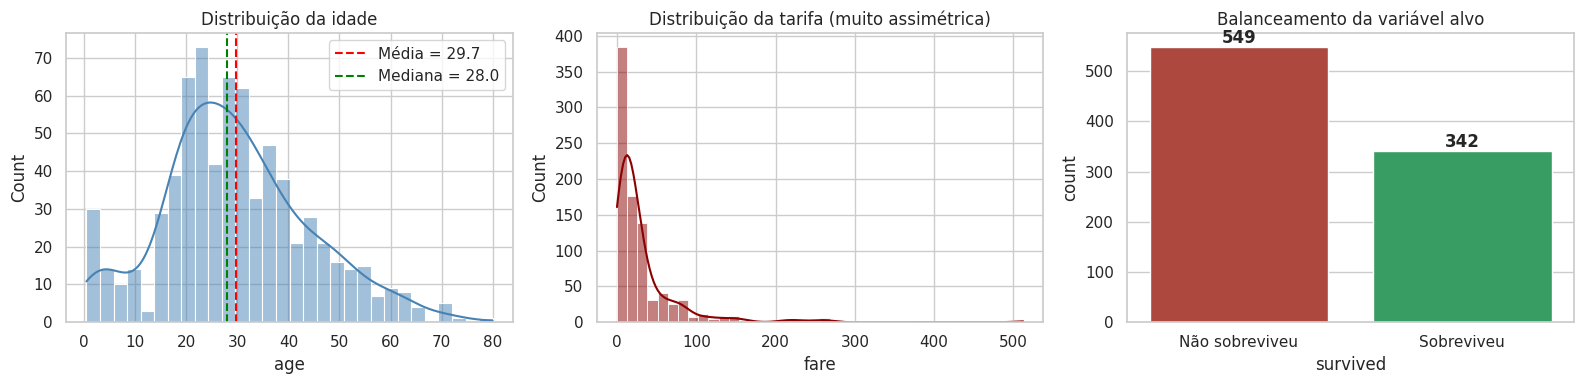

Taxa geral de sobrevivência: 38.4%


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["age"].dropna(), bins=30, kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(df["age"].mean(), color="red", ls="--", label=f"Média = {df['age'].mean():.1f}")
axes[0].axvline(df["age"].median(), color="green", ls="--", label=f"Mediana = {df['age'].median():.1f}")
axes[0].set_title("Distribuição da idade")
axes[0].legend()

sns.histplot(df["fare"], bins=40, kde=True, color="darkred", ax=axes[1])
axes[1].set_title("Distribuição da tarifa (muito assimétrica)")

sns.countplot(x="survived", data=df, palette=["#c0392b", "#27ae60"], ax=axes[2])
axes[2].set_xticklabels(["Não sobreviveu", "Sobreviveu"])
axes[2].set_title("Balanceamento da variável alvo")
for p in axes[2].patches:
    axes[2].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Taxa geral de sobrevivência: {df['survived'].mean():.1%}")

### 2.5 Outliers

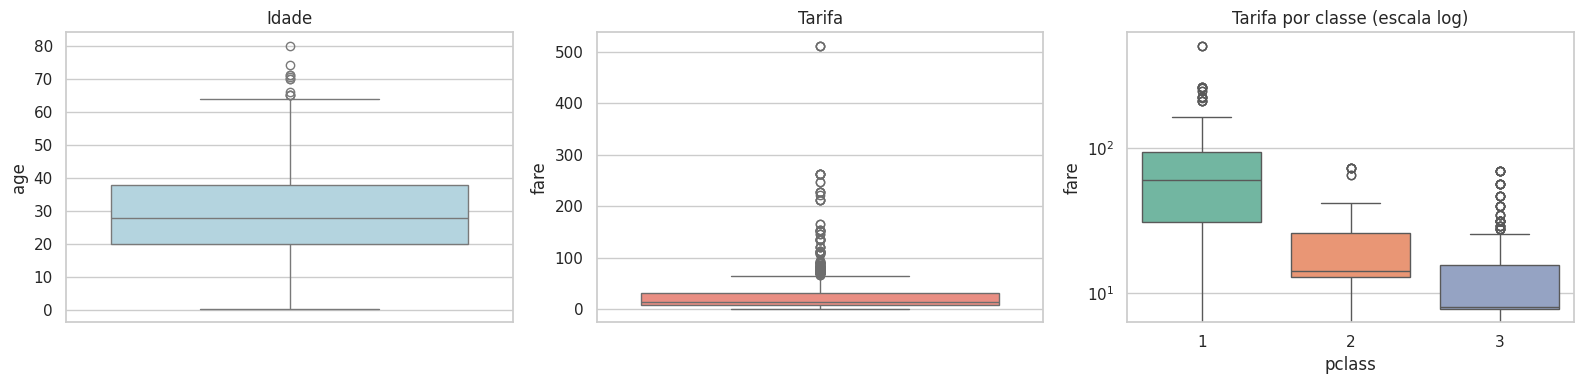

Outliers de tarifa (regra do IQR): 116 registros (13.0%)


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(y=df["age"], color="lightblue", ax=axes[0]);  axes[0].set_title("Idade")
sns.boxplot(y=df["fare"], color="salmon", ax=axes[1]);     axes[1].set_title("Tarifa")
sns.boxplot(x="pclass", y="fare", data=df, palette="Set2", ax=axes[2])
axes[2].set_yscale("log"); axes[2].set_title("Tarifa por classe (escala log)")
plt.tight_layout()
plt.show()

q1, q3 = df["fare"].quantile([.25, .75])
iqr = q3 - q1
out = df[df["fare"] > q3 + 1.5 * iqr]
print(f"Outliers de tarifa (regra do IQR): {len(out)} registros ({len(out)/len(df):.1%})")

### 2.6 Padrões de sobrevivência

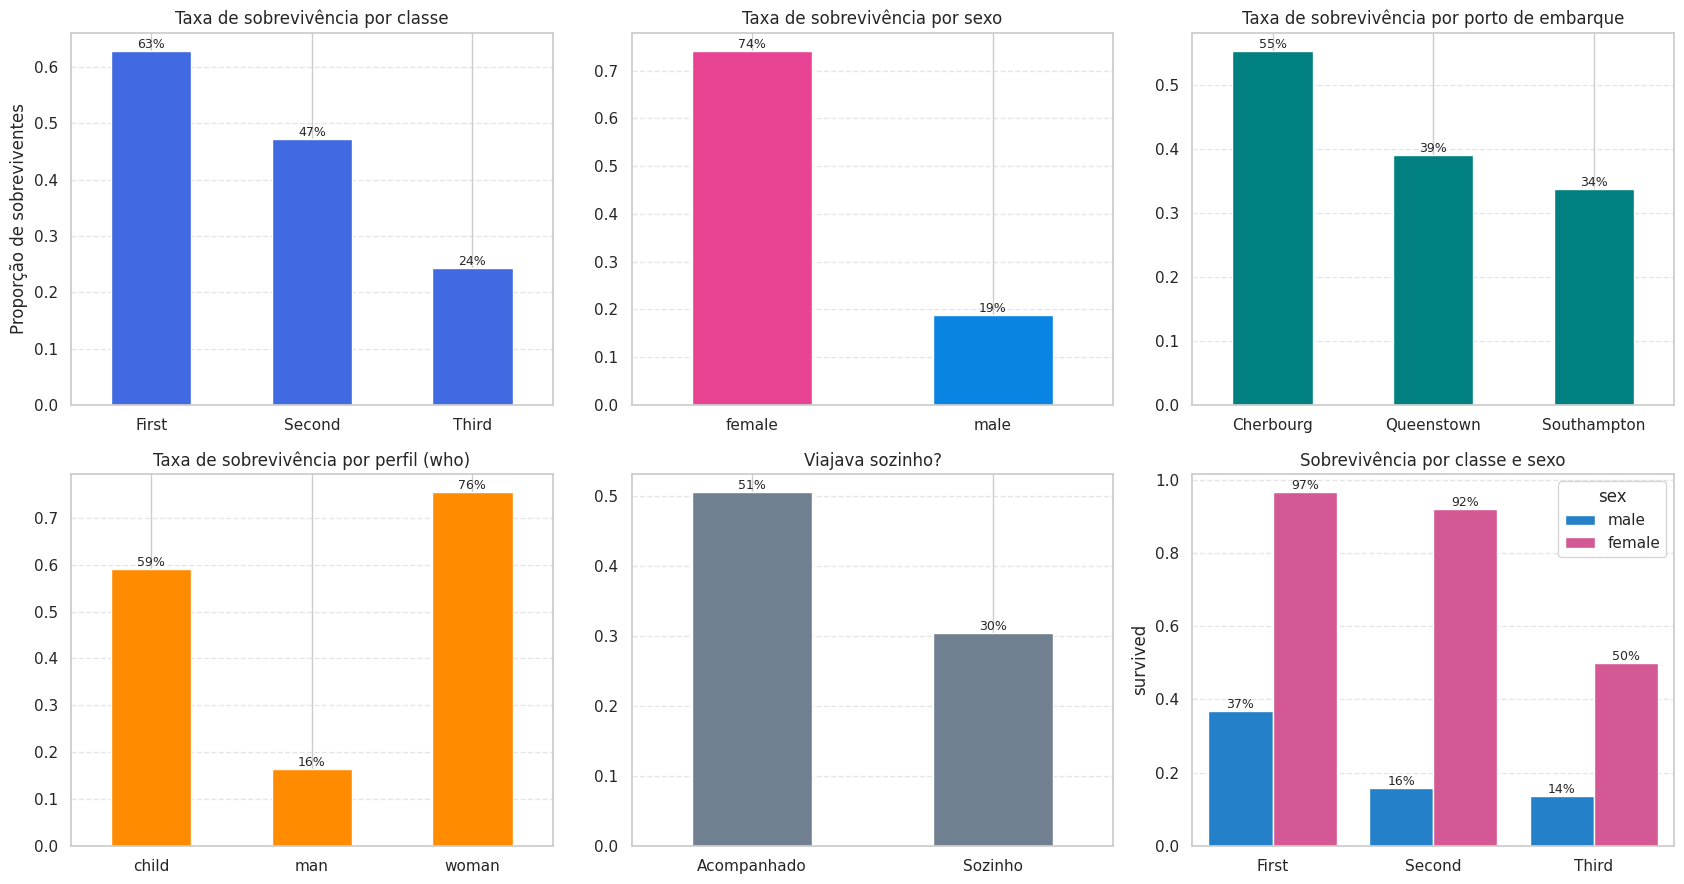

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

# Classe
df.groupby("class", observed=True)["survived"].mean().plot(kind="bar", color="royalblue", ax=axes[0, 0])
axes[0, 0].set_title("Taxa de sobrevivência por classe"); axes[0, 0].set_ylabel("Proporção de sobreviventes")

# Sexo
df.groupby("sex")["survived"].mean().plot(kind="bar", color=["#e84393", "#0984e3"], ax=axes[0, 1])
axes[0, 1].set_title("Taxa de sobrevivência por sexo")

# Porto de embarque
df.groupby("embark_town")["survived"].mean().plot(kind="bar", color="teal", ax=axes[0, 2])
axes[0, 2].set_title("Taxa de sobrevivência por porto de embarque")

# Who
df.groupby("who")["survived"].mean().plot(kind="bar", color="darkorange", ax=axes[1, 0])
axes[1, 0].set_title("Taxa de sobrevivência por perfil (who)")

# Sozinho
df.groupby("alone")["survived"].mean().plot(kind="bar", color="slategray", ax=axes[1, 1])
axes[1, 1].set_title("Viajava sozinho?")
axes[1, 1].set_xticklabels(["Acompanhado", "Sozinho"], rotation=0)

# Sexo x Classe
sns.barplot(x="class", y="survived", hue="sex", data=df, palette=["#0984e3", "#e84393"],
            errorbar=None, ax=axes[1, 2])
axes[1, 2].set_title("Sobrevivência por classe e sexo")

for ax in axes.flat:
    ax.set_xlabel("")
    ax.grid(axis="y", ls="--", alpha=.5)
    ax.tick_params(axis="x", rotation=0)
    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            ax.annotate(f"{h:.0%}", (p.get_x() + p.get_width() / 2, h), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

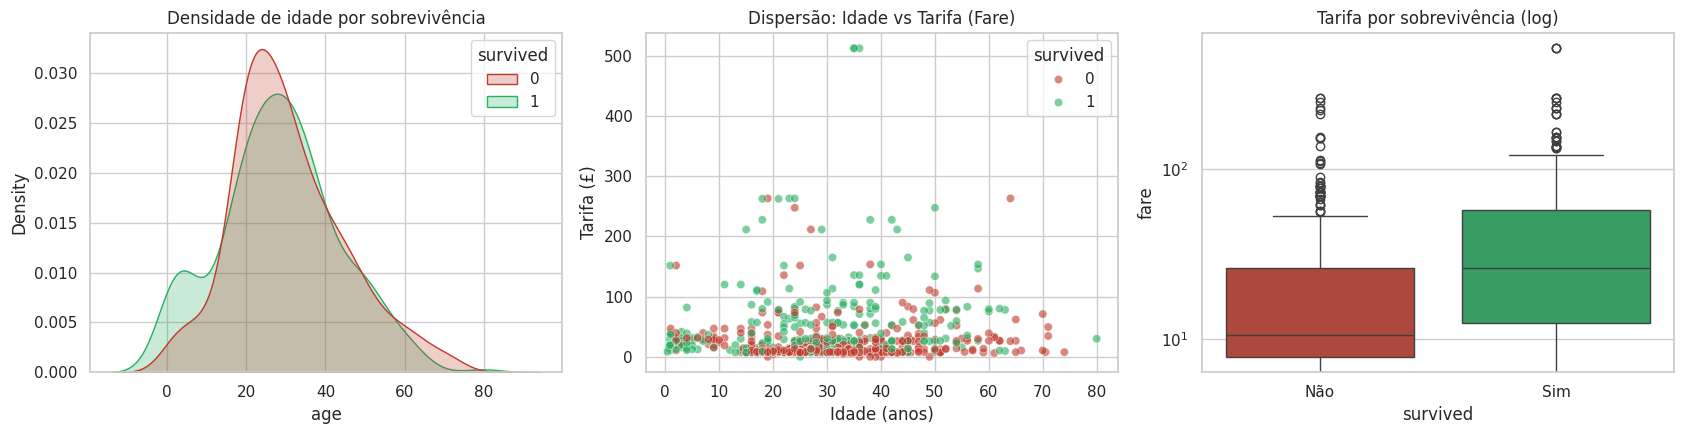

In [10]:
# Idade e tarifa vs sobrevivência
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.kdeplot(data=df, x="age", hue="survived", fill=True, common_norm=False,
            palette=["#c0392b", "#27ae60"], ax=axes[0])
axes[0].set_title("Densidade de idade por sobrevivência")

sns.scatterplot(data=df, x="age", y="fare", hue="survived", alpha=.6,
                palette=["#c0392b", "#27ae60"], ax=axes[1])
axes[1].set_title("Dispersão: Idade vs Tarifa (Fare)")
axes[1].set_xlabel("Idade (anos)"); axes[1].set_ylabel("Tarifa (£)")

sns.boxplot(x="survived", y="fare", data=df, palette=["#c0392b", "#27ae60"], ax=axes[2])
axes[2].set_yscale("log"); axes[2].set_title("Tarifa por sobrevivência (log)")
axes[2].set_xticklabels(["Não", "Sim"])
plt.tight_layout()
plt.show()

### 2.7 Correlações

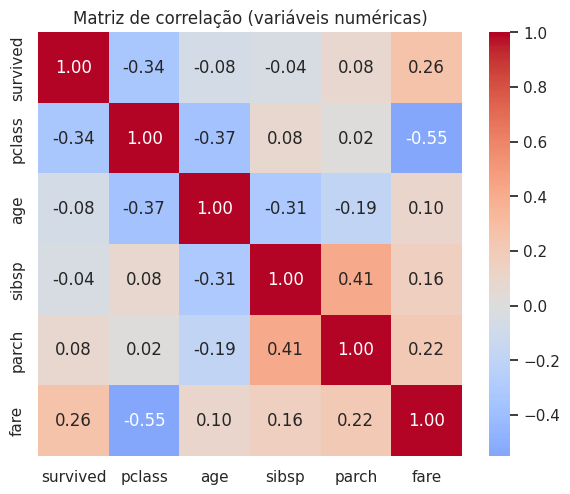

Correlação com 'survived':
pclass   -0.338
fare      0.257
parch     0.082
age      -0.077
sibsp    -0.035
Name: survived, dtype: float64


In [11]:
num = df.select_dtypes("number")
corr = num.corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Matriz de correlação (variáveis numéricas)")
plt.show()

print("Correlação com 'survived':")
print(corr["survived"].drop("survived").sort_values(key=abs, ascending=False).round(3))

#### Principais observações da EDA

- **Desbalanceamento moderado**: ~38% de sobreviventes.
- **Sexo** é o fator mais forte: mulheres sobreviveram em taxa muito superior à dos homens.
- **Classe**: quanto mais alta a classe, maior a taxa de sobrevivência (1ª > 2ª > 3ª). `pclass` e `fare` são fortemente correlacionadas entre si (negativamente).
- **Idade**: crianças tiveram melhor taxa; idosos, pior.
- **Tarifa** é muito assimétrica, com outliers (até ~£512), o que sugere uma transformação logarítmica.
- **`deck`** tem cerca de 77% de valores em falta; **`age`** cerca de 20%; **`embarked`** apenas 2 registros.

## 3. Tratamento e limpeza

In [12]:
# Trabalhamos em uma cópia para preservar os dados originais
df_raw = df.copy()
df_clean = df.copy()

# Registro das ações para o resumo final
acoes = []
def log(coluna, problema, acao, afetados):
    acoes.append({"Coluna": coluna, "Problema": problema, "Ação": acao, "Registros afetados": afetados})

### 3.1 Duplicados

In [13]:
n_dup = df_clean.duplicated().sum()
print(f"Linhas totalmente duplicadas: {n_dup}")

Linhas totalmente duplicadas: 107


> O dataset não possui identificador único (ex.: nome ou ID do passageiro). Por isso, as linhas "duplicadas" encontradas acima são **combinações idênticas de atributos** (ex.: dois passageiros adultos, solteiros, da 3ª classe, com a mesma tarifa), e não necessariamente o mesmo passageiro registrado duas vezes. Remover essas linhas eliminaria passageiros reais e distorceria a taxa de sobrevivência. **Decisão: manter.**

In [14]:
# Verificação: as linhas "duplicadas" são passageiros distintos plausíveis?
dups = df_clean[df_clean.duplicated(keep=False)].sort_values(list(df_clean.columns))
print(f"Linhas envolvidas em duplicações: {len(dups)}")
dups.head(6)

Linhas envolvidas em duplicações: 160


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
64,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
295,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
144,0,2,male,18.0,0,0,11.5000,S,Second,man,True,NaN,Southampton,no,True
757,0,2,male,18.0,0,0,11.5000,S,Second,man,True,NaN,Southampton,no,True
658,0,2,male,23.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
733,0,2,male,23.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True


In [15]:
log("(todas)", "Linhas idênticas sem ID único", "Mantidas (passageiros distintos, não duplicatas reais)", int(n_dup))

### 3.2 Valores em falta

**`embarked` / `embark_town` (2 nulos)** – imputação pela **moda** (porto mais frequente), pois são poucos registros.

In [16]:
print("Nulos antes:", df_clean["embarked"].isna().sum(), "| embark_town:", df_clean["embark_town"].isna().sum())
moda_emb = df_clean["embarked"].mode()[0]
moda_town = df_clean["embark_town"].mode()[0]
n = int(df_clean["embarked"].isna().sum())
df_clean["embarked"] = df_clean["embarked"].fillna(moda_emb)
df_clean["embark_town"] = df_clean["embark_town"].fillna(moda_town)
print(f"Imputado com a moda: {moda_emb} / {moda_town}")
log("embarked, embark_town", "2 valores nulos", f"Imputação pela moda ({moda_town})", n)

Nulos antes: 2 | embark_town: 2
Imputado com a moda: S / Southampton


**`age` (177 nulos, ~20%)** – a idade varia com classe e sexo, então imputamos pela **mediana do grupo (`pclass` × `sex`)**, em vez de uma mediana global. Antes, guardamos um **indicador de ausência** (`age_missing`), pois o fato de a idade estar ausente pode ser informativo.

In [17]:
print("Mediana de idade por grupo (pclass x sex):")
display(df_clean.groupby(["pclass", "sex"])["age"].median().unstack())

n_age = int(df_clean["age"].isna().sum())
df_clean["age_missing"] = df_clean["age"].isna().astype(int)
df_clean["age"] = df_clean.groupby(["pclass", "sex"])["age"].transform(lambda s: s.fillna(s.median()))

print("\nNulos em age após imputação:", df_clean["age"].isna().sum())
log("age", "177 nulos (19,9%)", "Imputação pela mediana por grupo (pclass x sex) + flag age_missing", n_age)

Mediana de idade por grupo (pclass x sex):


sex,female,male
pclass,,
1,35.0,40.0
2,28.0,30.0
3,21.5,25.0



Nulos em age após imputação: 0


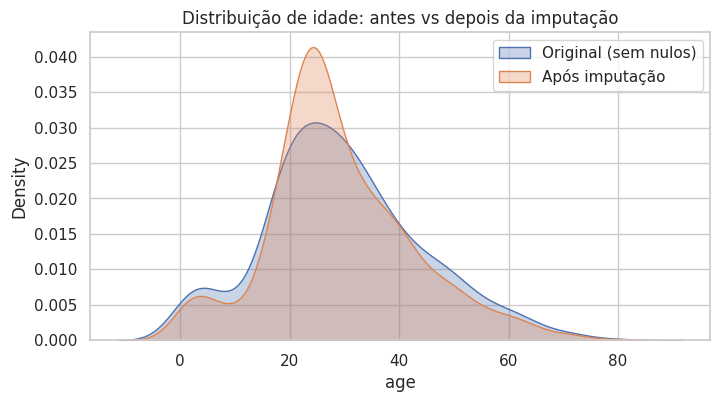

In [18]:
# Verificar se a imputação preservou a distribuição
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(df_raw["age"].dropna(), label="Original (sem nulos)", fill=True, alpha=.3, ax=ax)
sns.kdeplot(df_clean["age"], label="Após imputação", fill=True, alpha=.3, ax=ax)
ax.set_title("Distribuição de idade: antes vs depois da imputação"); ax.legend()
plt.show()

**`deck` (688 nulos, ~77%)** – proporção de ausentes muito alta; imputar criaria informação artificial. **Decisão:** manter apenas um indicador binário `has_cabin` (cabine registrada ou não, que se correlaciona com a classe) e **remover a coluna `deck`**.

In [19]:
n_deck = int(df_clean["deck"].isna().sum())
df_clean["has_cabin"] = df_clean["deck"].notna().astype(int)
print("Taxa de sobrevivência por has_cabin:")
print(df_clean.groupby("has_cabin")["survived"].mean().round(3))
df_clean = df_clean.drop(columns="deck")
log("deck", "688 nulos (77,2%)", "Coluna removida; criado indicador binário has_cabin", n_deck)

Taxa de sobrevivência por has_cabin:
has_cabin
0    0.299
1    0.670
Name: survived, dtype: float64


### 3.3 Redundâncias e inconsistências

In [20]:
# Colunas que representam a mesma informação
print("survived == alive      :", (df_clean["survived"] == df_clean["alive"].map({"yes": 1, "no": 0})).all())
print("pclass  == class       :", (df_clean["pclass"] == df_clean["class"].map({"First": 1, "Second": 2, "Third": 3}).astype(int)).all())
print("embarked <-> embark_town:", df_clean.groupby("embarked")["embark_town"].nunique().eq(1).all())
print("adult_male == (who=='man'):", (df_clean["adult_male"] == (df_clean["who"] == "man")).all())
print("alone == (sibsp+parch==0):", (df_clean["alone"] == ((df_clean["sibsp"] + df_clean["parch"]) == 0)).all())

survived == alive      : True
pclass  == class       : True
embarked <-> embark_town: True


adult_male == (who=='man'): True
alone == (sibsp+parch==0): True


In [21]:
# Remoção de colunas redundantes
redundantes = ["alive", "class", "embark_town", "adult_male"]
df_clean = df_clean.drop(columns=redundantes)
log("alive, class, embark_town, adult_male", "Redundantes (duplicam survived, pclass, embarked e who)",
    "Colunas removidas", len(redundantes))

In [22]:
# Inconsistências de valores
print("Idades <= 0 ou > 100:", ((df_clean["age"] <= 0) | (df_clean["age"] > 100)).sum())
print("Idades fracionárias (bebês < 1 ano, ou estimadas):", (df_clean["age"] % 1 != 0).sum())
print("Tarifas = 0:", (df_clean["fare"] == 0).sum())
print("Tarifas negativas:", (df_clean["fare"] < 0).sum())
display(df_clean[df_clean["fare"] == 0][["survived", "pclass", "sex", "age", "fare", "embarked"]])

Idades <= 0 ou > 100: 0
Idades fracionárias (bebês < 1 ano, ou estimadas): 67
Tarifas = 0: 15
Tarifas negativas: 0


,survived,pclass,sex,age,fare,embarked
179,0,3,male,36.0,0.0,S
263,0,1,male,40.0,0.0,S
271,1,3,male,25.0,0.0,S
277,0,2,male,30.0,0.0,S
302,0,3,male,19.0,0.0,S
413,0,2,male,30.0,0.0,S
466,0,2,male,30.0,0.0,S
481,0,2,male,30.0,0.0,S
597,0,3,male,49.0,0.0,S
633,0,1,male,40.0,0.0,S


> As **15 tarifas iguais a zero** correspondem a viagens sem cobrança (tripulação/funcionários da empresa ou convidados, conforme registros históricos), portanto são **dados legítimos** e não erros. Mantemos os registros. Na transformação logarítmica usaremos `log1p`, que lida com zeros.

In [23]:
log("fare", "15 tarifas = 0", "Mantidas (dados legítimos); uso de log1p na transformação", int((df_clean['fare'] == 0).sum()))
log("age", "Idades fracionárias (bebês)", "Mantidas (válidas); nenhuma idade fora do intervalo 0-100", int((df_clean['age'] % 1 != 0).sum()))

### 3.4 Resumo das ações de limpeza

In [24]:
resumo = pd.DataFrame(acoes)
display(resumo.style.set_properties(**{"text-align": "left"}).hide(axis="index"))

print(f"\nDimensões antes : {df_raw.shape}")
print(f"Dimensões depois: {df_clean.shape}")
print(f"Nulos restantes : {int(df_clean.isna().sum().sum())}")

Coluna,Problema,Ação,Registros afetados
(todas),Linhas idênticas sem ID único,"Mantidas (passageiros distintos, não duplicatas reais)",107
"embarked, embark_town",2 valores nulos,Imputação pela moda (Southampton),2
age,"177 nulos (19,9%)",Imputação pela mediana por grupo (pclass x sex) + flag age_missing,177
deck,"688 nulos (77,2%)",Coluna removida; criado indicador binário has_cabin,688
"alive, class, embark_town, adult_male","Redundantes (duplicam survived, pclass, embarked e who)",Colunas removidas,4
fare,15 tarifas = 0,Mantidas (dados legítimos); uso de log1p na transformação,15
age,Idades fracionárias (bebês),Mantidas (válidas); nenhuma idade fora do intervalo 0-100,67



Dimensões antes : (891, 15)
Dimensões depois: (891, 12)
Nulos restantes : 0


## 4. Feature Engineering

In [25]:
df_fe = df_clean.copy()

### 4.1 Agregação de laços familiares

`family_size` = irmãos/cônjuges + pais/filhos + o próprio passageiro. Em seguida, categorizamos o tamanho da família.

family_category
Sozinho (1)        537
Pequena (2 a 4)    292
Grande (5+)         62
Name: count, dtype: int64


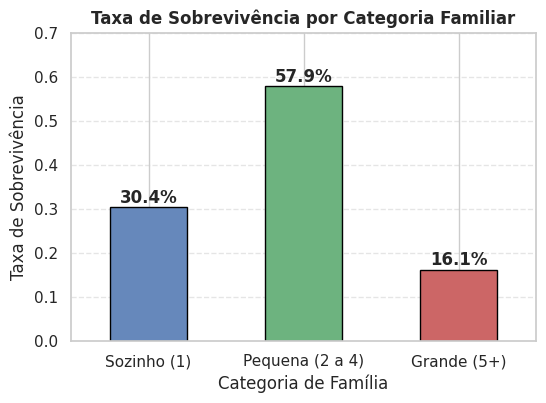

In [26]:
df_fe["family_size"] = df_fe["sibsp"] + df_fe["parch"] + 1

df_fe["family_category"] = pd.cut(
    df_fe["family_size"],
    bins=[0, 1, 4, np.inf],
    labels=["Sozinho (1)", "Pequena (2 a 4)", "Grande (5+)"],
)

print(df_fe["family_category"].value_counts())

taxa_fam = df_fe.groupby("family_category", observed=True)["survived"].mean()
ax = taxa_fam.plot(kind="bar", color=["#6688bb", "#6db37f", "#cc6666"], edgecolor="black", figsize=(6, 4))
ax.set_title("Taxa de Sobrevivência por Categoria Familiar", fontweight="bold")
ax.set_ylabel("Taxa de Sobrevivência"); ax.set_xlabel("Categoria de Família")
ax.set_ylim(0, 0.7); ax.tick_params(axis="x", rotation=0); ax.grid(axis="y", ls="--", alpha=.5)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1%}", (p.get_x() + p.get_width() / 2, p.get_height() + .01),
                ha="center", fontweight="bold")
plt.show()

> Famílias **pequenas (2 a 4)** tiveram a maior taxa de sobrevivência; quem viajava **sozinho** ou em **famílias grandes (5+)** teve resultados bem piores, uma relação **não linear** que justifica criar a categoria em vez de usar só o número bruto.

### 4.2 Agrupamento etário (binning)

age_group
Adulto         752
Criança         68
Adolescente     45
Idoso           26
Name: count, dtype: int64


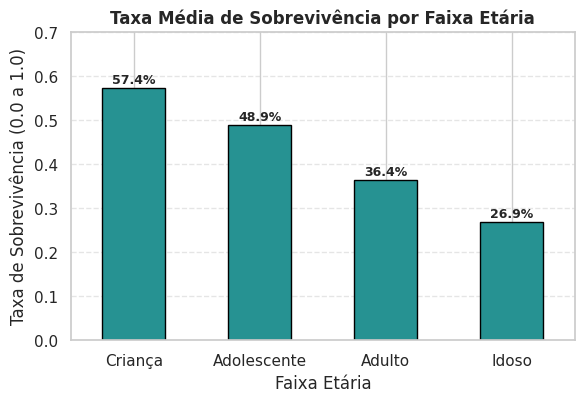

In [27]:
df_fe["age_group"] = pd.cut(
    df_fe["age"],
    bins=[0, 12, 18, 60, 120],
    labels=["Criança", "Adolescente", "Adulto", "Idoso"],
    right=False,
)
print(df_fe["age_group"].value_counts())

taxa_age = df_fe.groupby("age_group", observed=True)["survived"].mean()
ax = taxa_age.plot(kind="bar", color="#269292", edgecolor="black", figsize=(6.5, 4))
ax.set_title("Taxa Média de Sobrevivência por Faixa Etária", fontweight="bold")
ax.set_ylabel("Taxa de Sobrevivência (0.0 a 1.0)"); ax.set_xlabel("Faixa Etária")
ax.set_ylim(0, 0.7); ax.tick_params(axis="x", rotation=0); ax.grid(axis="y", ls="--", alpha=.5)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1%}", (p.get_x() + p.get_width() / 2, p.get_height() + .01),
                ha="center", fontweight="bold", fontsize=9)
plt.show()

### 4.3 Outras transformações

Assimetria de fare     : 4.79
Assimetria de fare_log : 0.39


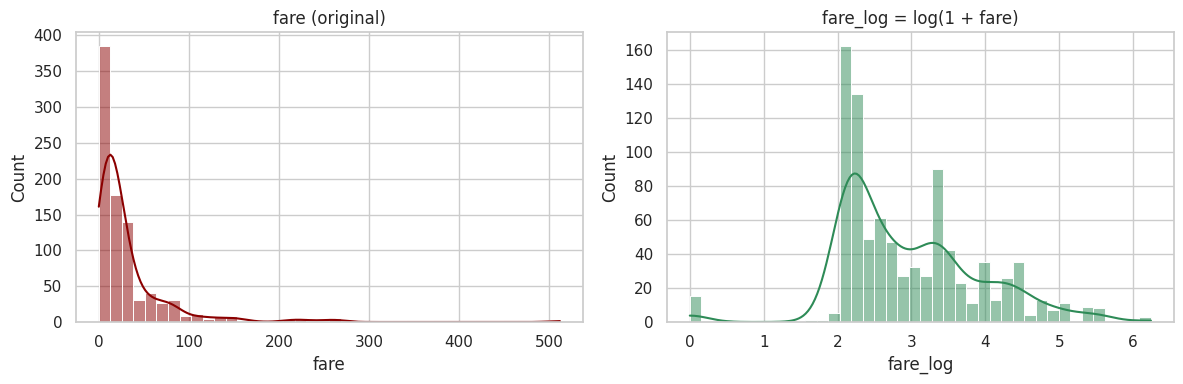

In [28]:
# Tarifa: transformação log (reduz assimetria) e tarifa por pessoa
df_fe["fare_log"] = np.log1p(df_fe["fare"])
df_fe["fare_per_person"] = df_fe["fare"] / df_fe["family_size"]

# Faixas de tarifa por quartis
df_fe["fare_bin"] = pd.qcut(df_fe["fare"], q=4, labels=["Q1 (baixa)", "Q2", "Q3", "Q4 (alta)"])

print(f"Assimetria de fare     : {df_fe['fare'].skew():.2f}")
print(f"Assimetria de fare_log : {df_fe['fare_log'].skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_fe["fare"], bins=40, kde=True, color="darkred", ax=axes[0]); axes[0].set_title("fare (original)")
sns.histplot(df_fe["fare_log"], bins=40, kde=True, color="seagreen", ax=axes[1]); axes[1].set_title("fare_log = log(1 + fare)")
plt.tight_layout(); plt.show()

### 4.4 Codificação binária e categórica

In [29]:
# Binária: sexo, alone (bool) e demais booleanos -> 0/1
df_fe["sex_male"] = (df_fe["sex"] == "male").astype(int)
df_fe["is_alone"] = df_fe["alone"].astype(int)

# One-hot: porto de embarque, perfil (who), faixa etária, categoria familiar
df_fe = pd.get_dummies(
    df_fe,
    columns=["embarked", "who", "age_group", "family_category", "fare_bin"],
    prefix=["emb", "who", "age", "fam", "fare"],
    dtype=int,
)

# Remover colunas originais já codificadas/redundantes
df_fe = df_fe.drop(columns=["sex", "alone"])
df_fe.head()

,survived,pclass,age,sibsp,parch,fare,age_missing,has_cabin,family_size,fare_log,...,age_Adolescente,age_Adulto,age_Idoso,fam_Sozinho (1),fam_Pequena (2 a 4),fam_Grande (5+),fare_Q1 (baixa),fare_Q2,fare_Q3,fare_Q4 (alta)
0,0,3,22.0,1,0,7.2500,0,0,2,2.110213,...,0,1,0,0,1,0,1,0,0,0
1,1,1,38.0,1,0,71.2833,0,1,2,4.280593,...,0,1,0,0,1,0,0,0,0,1
2,1,3,26.0,0,0,7.9250,0,0,1,2.188856,...,0,1,0,1,0,0,0,1,0,0
3,1,1,35.0,1,0,53.1000,0,1,2,3.990834,...,0,1,0,0,1,0,0,0,0,1
4,0,3,35.0,0,0,8.0500,0,0,1,2.202765,...,0,1,0,1,0,0,0,1,0,0


### 4.5 Dataset final

In [30]:
print(f"Dimensões finais: {df_fe.shape}")
print(f"Nulos: {int(df_fe.isna().sum().sum())}")
print("\nTipos de dados:")
print(df_fe.dtypes.value_counts())
print("\nColunas:", list(df_fe.columns))

Dimensões finais: (891, 30)
Nulos: 0

Tipos de dados:
int64      26
float64     4
Name: count, dtype: int64

Colunas: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'age_missing', 'has_cabin', 'family_size', 'fare_log', 'fare_per_person', 'sex_male', 'is_alone', 'emb_C', 'emb_Q', 'emb_S', 'who_child', 'who_man', 'who_woman', 'age_Criança', 'age_Adolescente', 'age_Adulto', 'age_Idoso', 'fam_Sozinho (1)', 'fam_Pequena (2 a 4)', 'fam_Grande (5+)', 'fare_Q1 (baixa)', 'fare_Q2', 'fare_Q3', 'fare_Q4 (alta)']


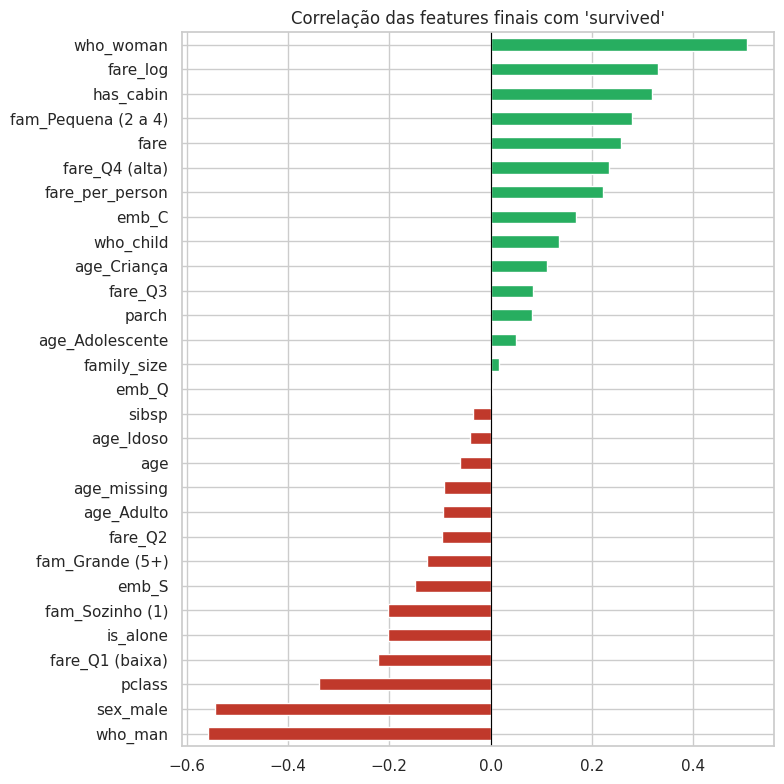

In [31]:
# Correlação das novas features com a variável alvo
corr_final = df_fe.corr()["survived"].drop("survived").sort_values()

fig, ax = plt.subplots(figsize=(8, 8))
colors = ["#c0392b" if v < 0 else "#27ae60" for v in corr_final]
corr_final.plot(kind="barh", color=colors, ax=ax)
ax.set_title("Correlação das features finais com 'survived'")
ax.axvline(0, color="black", lw=.8)
plt.tight_layout(); plt.show()

In [32]:
# Exportar o dataset preparado para a etapa de modelagem
df_fe.to_csv("titanic_preparado.csv", index=False)
print("Arquivo salvo: titanic_preparado.csv")

Arquivo salvo: titanic_preparado.csv


## 5. Conclusões

**EDA**
- Taxa geral de sobrevivência de ~38%. Os principais fatores associados foram **sexo** (mulheres ≫ homens), **classe** (1ª > 2ª > 3ª) e **idade** (crianças favorecidas).
- A tarifa é altamente assimétrica e correlacionada com a classe.

**Limpeza**
- `embarked`: moda; `age`: mediana por `pclass × sex` + flag `age_missing`; `deck`: removida (77% nulos) e substituída por `has_cabin`.
- Removidas 4 colunas redundantes (`alive`, `class`, `embark_town`, `adult_male`).
- Linhas "duplicadas" mantidas (sem ID único, são passageiros distintos); tarifas zero mantidas (dados legítimos).

**Feature Engineering**
- `family_size`, `family_category` (relação não linear com sobrevivência), `is_alone`.
- `age_group` por binning, `fare_log`, `fare_per_person`, `fare_bin`.
- Codificação binária (`sex_male`, `is_alone`) e one-hot (porto, perfil, faixa etária, família, faixa de tarifa).

O dataset resultante está **100% numérico, sem nulos**, pronto para modelagem preditiva (ex.: Regressão Logística, Árvores de Decisão, Random Forest).

> **Atenção para a modelagem:** `who_*` e `age_*` carregam informação sobreposta com `age` e `sex_male`, e `family_size`/`is_alone`/`fam_*` também se sobrepõem. Em modelos lineares, vale escolher um subconjunto para evitar multicolinearidade.